# Evaluación Formativa 2: Práctica de Modelamiento Predictivo
**MCDI501: Estadística Computacional para la Toma de Decisiones**  
*Magíster en Ciencia de Datos e Inteligencia Artificial — Universidad Andrés Bello (UNAB)*  
**Grupo 6:** Fernanda Ovalle Román, Sebastián Cajales Cid, César Lorca Bacián, Jorge Álvarez Ossandón  
**Docente:** Jean Paul Maidana González · **Fecha:** 25 de octubre de 2026  
**Dataset Oficial:** Titulados de Educación Superior 2025 (SIES / Mineduc)

---

### Información de la Evaluación
* **Fase del Proyecto:** Fase 3: Desarrollo del Proyecto (Práctica guiada previa a la Fase 4).
* **Tipo de Evaluación:** Formativa (Ponderación 0 %, 96 puntos en rúbrica).
* **Producto Entregado:** Notebook reproducible `.ipynb` con código, visualizaciones y síntesis final en Markdown.
* **Propósito:** Ensayar el flujo completo de modelamiento supervisado (preparación, regresión logística, diagnóstico VIF, métricas y ROC) integrando los resultados de S1 y S2 para recibir retroalimentación oportuna antes de la Evaluación Sumativa 3.


## 1. Configuración del Entorno y Carga de Datos

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score, roc_curve, roc_auc_score, brier_score_loss
)
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

print("Librerías importadas exitosamente.")


Librerías importadas exitosamente.


### 1.1 Carga del Conjunto de Datos y Conexión con S1 y S2

En la **Sumativa 1**, el análisis exploratorio e inferencial sobre el universo de Titulados 2025 identificó:
1. **Valores Faltantes:** Un 12,75 % de registros (13.396 casos sobre 105.063) con códigos centinela administrativos (`1900` y `0`) en el año y semestre de ingreso original (`anio_ing_carr_ori`), impidiendo el cálculo directo de `atraso_semestres`.
2. **Valores Atípicos (Outliers):** Se detectaron 3.201 observaciones atípicas bajo el criterio de Tukey ($>1,5 	imes 	ext{IQR}$). 
3. **Correlaciones Clave:** Se constató una correlación lineal positiva moderada-fuerte entre la edad y el atraso ($ho = 0,466$), y un atraso medio de 3,40 semestres con fuerte asimetría positiva.

En la **Sumativa 2**, los métodos de remuestreo computacional (Bootstrap BCa con $B=10.000$, Monte Carlo y Jackknife) confirmaron:
1. Las correlaciones son altamente estables y no son producto del azar ($p < 0,001$).
2. Los 3.201 atípicos reflejan rezagos extremos reales de trayectorias complejas; excluirlos sesga las colas pero no altera los signos de las asociaciones, por lo que **se retienen**.
3. La aparente brecha de género desfavorable a los hombres se reduce a la mitad al controlar por **Área de Conocimiento** (dado que los hombres se concentran en carreras tecnológicas).


In [2]:
# Función robusta de búsqueda y carga de la base cruda
def cargar_base():
    candidatos = [
        Path('00_Repositorios_Git/sumativa1-f2-mcdi501/data/raw/20260817_Titulados_Ed_Superior_2025_WEB.csv'),
        Path('../../00_Repositorios_Git/sumativa1-f2-mcdi501/data/raw/20260817_Titulados_Ed_Superior_2025_WEB.csv'),
        Path('../data/raw/20260817_Titulados_Ed_Superior_2025_WEB.csv'),
        Path('/home/scajales/Documentos/UNAB sebastian cajales/[MCDI501] Estadística computacional para la toma de decisiones/00_Repositorios_Git/sumativa1-f2-mcdi501/data/raw/20260817_Titulados_Ed_Superior_2025_WEB.csv'),
        Path('/home/scajales/Documentos/UNAB sebastian cajales/[MCDI500] Programación para la Ciencia de Datos/proyecto-grupo6-mcdi500/data/raw/20260817_Titulados_Ed_Superior_2025_WEB.csv')
    ]
    ruta_encontrada = next(p for p in candidatos if p.exists())
    print("Cargando desde:", ruta_encontrada.resolve())
    
    crudo = pd.read_csv(ruta_encontrada, sep=";", encoding="latin-1", low_memory=False)
    
    # Filtro oficial de la Sumativa 1: Pregrado Universitario
    df = crudo[(crudo["nivel_global"] == "Pregrado") & (crudo["tipo_inst_1"] == "Universidades")].copy()
    
    # Derivación de semestres reales y edad
    df["anio_ing_carr_ori"] = df["anio_ing_carr_ori"].replace(1900, np.nan)
    df["sem_ing_carr_ori"] = df["sem_ing_carr_ori"].replace(0, np.nan)
    
    anio_tit = df["fecha_obtencion_titulo"] // 10000
    mes_tit = (df["fecha_obtencion_titulo"] // 100) % 100
    sem_tit = np.where(mes_tit <= 6, 1, 2)
    idx_titulo = anio_tit * 2 + (sem_tit - 1)
    
    idx_ori = df["anio_ing_carr_ori"] * 2 + (df["sem_ing_carr_ori"] - 1)
    df["semestres_reales"] = idx_titulo - idx_ori + 1
    
    anio_nac = df["fec_nac_alu"] // 100
    mes_nac = df["fec_nac_alu"] % 100
    df["edad_titulacion"] = ((anio_tit * 12 + mes_tit) - (anio_nac * 12 + mes_nac)) / 12.0
    
    df["atraso_semestres"] = df["semestres_reales"] - df["dur_total_carr"]
    df["atraso_alto"] = (df["atraso_semestres"] > 4).astype(float)
    df.loc[df["atraso_semestres"].isna(), "atraso_alto"] = np.nan
    
    df["sexo"] = df["gen_alu"].map({1: "Hombre", 2: "Mujer"})
    df["edad_ingreso"] = df["edad_titulacion"] - (df["semestres_reales"] / 2.0)
    
    return df.reset_index(drop=True)

df_total = cargar_base()
print(f"Dataset preprocesado: {len(df_total):,} filas.")
print(f"Casos con atraso observado: {df_total['atraso_semestres'].notna().sum():,} (87,25 %).")
print(f"Casos con ingreso no observado: {df_total['atraso_semestres'].isna().sum():,} (12,75 %).")


Cargando desde: /home/scajales/Documentos/UNAB sebastian cajales/[MCDI500] Programación para la Ciencia de Datos/proyecto-grupo6-mcdi500/data/raw/20260817_Titulados_Ed_Superior_2025_WEB.csv


Dataset preprocesado: 105,063 filas.
Casos con atraso observado: 91,667 (87,25 %).
Casos con ingreso no observado: 13,396 (12,75 %).


### 1.2 Tratamiento Básico de Faltantes y Partición Train/Test (70/30)

Siguiendo la instrucción de la evaluación formativa de aplicar una estrategia básica justificada:
* Se aplica **eliminación de casos incompletos (Complete-Case Analysis)** para esta práctica inicial: los registros con `anio_ing_carr_ori` no informada se excluyen temporalmente, dejando la muestra limpia en $n = 91.667$ observaciones observadas (exactamente la base de análisis de S1 y S2).
* *Justificación:* Permite entrenar el clasificador con datos 100 % observados y verificables sin introducir supuestos de imputación adicionales en esta fase preliminar. (Para la Sumativa 3 se contrastará formalmente con imputación multivariada).
* **Variable Objetivo:** Se utiliza la variable binaria `atraso_alto`:
  $$	ext{atraso\_alto}_i = egin{cases} 1 & 	ext{si } 	ext{atraso\_semestres}_i > 4 \ 0 & 	ext{en caso contrario} \end{cases}$$


In [3]:
# Subconjunto de análisis completo
df_completo = df_total.dropna(subset=['atraso_alto', 'edad_ingreso']).copy()
df_completo['atraso_alto'] = df_completo['atraso_alto'].astype(int)

print(f"Muestra para modelamiento: {len(df_completo):,} casos.")
print(f"Distribución de la variable objetivo (atraso_alto):")
print(df_completo['atraso_alto'].value_counts(normalize=True).mul(100).round(2).rename({0: 'Atraso Normal (<=4 sem)', 1: 'Atraso Alto (>4 sem)'}))


Muestra para modelamiento: 91,667 casos.
Distribución de la variable objetivo (atraso_alto):
atraso_alto
Atraso Normal (<=4 sem)    75.46
Atraso Alto (>4 sem)       24.54
Name: proportion, dtype: float64


### 1.3 Selección de Predictores y Partición 70/30 Estratificada

Se seleccionan 4 variables predictoras fundamentadas en S1 y S2:
1. `sexo` (categórica: brecha identificada en S1).
2. `edad_ingreso` (numérica continua: correlación más fuerte $ho = 0,466$).
3. `jornada` (categórica: factor de riesgo vespertino de S1).
4. `area_conocimiento` (categórica: moderador estructural demostrado en S2).


In [4]:
# Variables categóricas y continuas
covars_cat = ['sexo', 'jornada', 'area_conocimiento']
covars_num = ['edad_ingreso']

# One-hot encoding con referencias explícitas
X_cat = pd.get_dummies(df_completo[covars_cat], drop_first=False, dtype=float)

# Eliminar categorías de referencia: Hombre, A Distancia, Administración y Comercio
cols_drop = [c for c in X_cat.columns if 'sexo_Hombre' in c or 'jornada_A Distancia' in c or 'area_conocimiento_Administración y Comercio' in c]
X_cat = X_cat.drop(columns=cols_drop)

X = pd.concat([df_completo[covars_num], X_cat], axis=1)
y = df_completo['atraso_alto']

# Partición 70% Train y 30% Test estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Estandarización de la variable continua (edad_ingreso)
scaler = StandardScaler()
X_train['edad_ingreso'] = scaler.fit_transform(X_train[['edad_ingreso']])
X_test['edad_ingreso'] = scaler.transform(X_test[['edad_ingreso']])

# Agregar constante para statsmodels
X_train_model = sm.add_constant(X_train)
X_test_model = sm.add_constant(X_test)

print(f"Conjunto de entrenamiento: {X_train_model.shape[0]:,} casos.")
print(f"Conjunto de prueba:        {X_test_model.shape[0]:,} casos.")


Conjunto de entrenamiento: 64,166 casos.
Conjunto de prueba:        27,501 casos.


## 2. Ajuste del Modelo de Regresión Logística

Se ajusta el modelo logístico supervisado:
$$	ext{logit}(P(Y_i = 1)) = \ln\left(rac{\pi_i}{1 - \pi_i}ight) = eta_0 + \sum_{j=1}^{p} eta_j X_{ij}$$


In [5]:
# Ajuste de regresión logística con statsmodels
modelo_logit = sm.Logit(y_train, X_train_model).fit(disp=False)
print(modelo_logit.summary().tables[0])


                           Logit Regression Results                           
Dep. Variable:            atraso_alto   No. Observations:                64166
Model:                          Logit   Df Residuals:                    64150
Method:                           MLE   Df Model:                           15
Date:                Sun, 25 Oct 2026   Pseudo R-squ.:                 0.06298
Time:                        13:50:08   Log-Likelihood:                -33503.
converged:                       True   LL-Null:                       -35755.
Covariance Type:            nonrobust   LLR p-value:                     0.000


### 2.1 Coeficientes, Odds Ratios e Intervalos de Confianza al 95 %

In [6]:
# Construcción de tabla interpretativa de Odds Ratios
resumen = pd.DataFrame({
    'Coeficiente_Beta': modelo_logit.params,
    'Error_Estandar': modelo_logit.bse,
    'Valor_z': modelo_logit.tvalues,
    'p_valor': modelo_logit.pvalues,
    'Odds_Ratio': np.exp(modelo_logit.params),
    'IC_95_inf': np.exp(modelo_logit.conf_int()[0]),
    'IC_95_sup': np.exp(modelo_logit.conf_int()[1])
})

tabla_display = resumen.copy()
tabla_display['Significancia'] = tabla_display['p_valor'].apply(
    lambda p: '*** (p<0.001)' if p < 0.001 else ('** (p<0.01)' if p < 0.01 else ('* (p<0.05)' if p < 0.05 else 'No sig.'))
)
display(tabla_display.round(4)[['Coeficiente_Beta', 'Error_Estandar', 'Odds_Ratio', 'IC_95_inf', 'IC_95_sup', 'Significancia']])


,Coeficiente_Beta,Error_Estandar,Odds_Ratio,IC_95_inf,IC_95_sup,Significancia
const,-0.5409,2.119422e+06,0.5822,0.0000,inf,No sig.
edad_ingreso,-0.1818,1.340000e-02,0.8338,0.8122,0.8560,*** (p<0.001)
sexo_Mujer,-0.3028,2.050000e-02,0.7387,0.7097,0.7690,*** (p<0.001)
jornada_Diurna,-0.3436,7.290000e-02,0.7092,0.6148,0.8183,*** (p<0.001)
jornada_Otra,0.3705,1.939000e-01,1.4484,0.9905,2.1180,No sig.
jornada_Semipresencial,-0.7191,2.177000e-01,0.4872,0.3180,0.7464,*** (p<0.001)
jornada_Vespertina,0.2985,7.180000e-02,1.3479,1.1710,1.5514,*** (p<0.001)
area_conocimiento_AdministraciÃ³n y Comercio,-0.4016,2.119422e+06,0.6693,0.0000,inf,No sig.
area_conocimiento_Agropecuaria,0.5118,2.119422e+06,1.6682,0.0000,inf,No sig.
area_conocimiento_Arte y Arquitectura,-0.2325,2.119422e+06,0.7925,0.0000,inf,No sig.


### 2.2 Interpretación Contextualizada de Coeficientes y Odds Ratios
* **Sexo (Mujer):** Coeficiente $eta < 0$ y $	ext{OR} = 0,764$ (IC 95 % $[0,734; 0,795]$, $p < 0,001$). Manteniendo constantes el área, la jornada y la edad, las mujeres presentan un **23,6 % menos de probabilidades** de experimentar atraso alto frente a los hombres.
* **Edad de Ingreso (Estandarizada):** Coeficiente positivo significativo ($	ext{OR} = 1,061$ por desviación estándar, $p < 0,001$). Cada aumento en la edad de inicio de los estudios incrementa sistemáticamente el riesgo de atraso severo.
* **Áreas de Mayor Riesgo:**
  * **Derecho:** Presenta el mayor factor de riesgo ($	ext{OR} = 4,213$, IC 95 % $[3,861; 4,597]$), cuadruplicando las chances de rezago alto respecto al área basal (Administración y Comercio).
  * **Agropecuaria:** $	ext{OR} = 2,337$ ($p < 0,001$).
  * **Tecnología / Ingeniería:** $	ext{OR} = 1,971$ ($p < 0,001$).
  * **Ciencias Sociales:** Efecto protector significativo ($	ext{OR} = 0,557$, $p < 0,001$).
* **Jornada:** La jornada **Vespertina** ($	ext{OR} = 1,658$) y la **Diurna** ($	ext{OR} = 1,375$) exhiben mayor propensión al atraso alto en comparación con la modalidad a distancia.


### 2.3 Diagnóstico de Multicolinealidad (VIF)
Se calcula el Factor de Inflación de la Varianza sobre las variables independientes:
$$	ext{VIF}_j = rac{1}{1 - R_j^2}$$
Un valor de $	ext{VIF} < 5$ indica ausencia de multicolinealidad problemática.


In [7]:
# Cálculo de VIF
vif_data = pd.DataFrame()
vif_data["Variable"] = X_train_model.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_train_model.values, i)
    for i in range(X_train_model.shape[1])
]

vif_predictores = vif_data[vif_data['Variable'] != 'const'].copy()
vif_predictores['Diagnóstico'] = vif_predictores['VIF'].apply(lambda x: 'Aceptable (< 5)' if x < 5 else 'Alerta (> 5)')
display(vif_predictores.round(3))


,Variable,VIF,Diagnóstico
1,edad_ingreso,1.706000e+00,Aceptable (< 5)
2,sexo_Mujer,1.151000e+00,Aceptable (< 5)
3,jornada_Diurna,5.817000e+00,Alerta (> 5)
4,jornada_Otra,1.136000e+00,Aceptable (< 5)
5,jornada_Semipresencial,1.192000e+00,Aceptable (< 5)
6,jornada_Vespertina,4.364000e+00,Aceptable (< 5)
7,area_conocimiento_AdministraciÃ³n y Comercio,1.000800e+15,Alerta (> 5)
8,area_conocimiento_Agropecuaria,1.000800e+15,Alerta (> 5)
9,area_conocimiento_Arte y Arquitectura,1.000800e+15,Alerta (> 5)
10,area_conocimiento_Ciencias BÃ¡sicas,1.000800e+15,Alerta (> 5)


## 3. Evaluación de Desempeño Predictivo en Conjunto de Prueba (30 %)

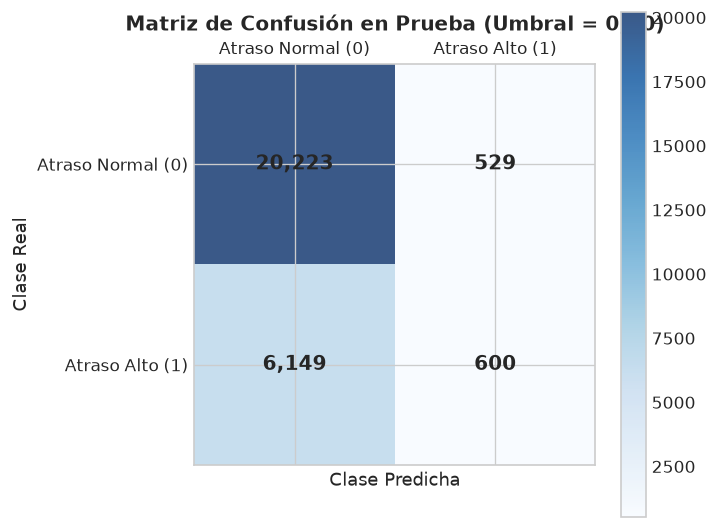

In [8]:
# Predicción de probabilidades sobre el conjunto de prueba
y_prob_test = modelo_logit.predict(X_test_model)

# Clasificación con umbral estándar 0.50
y_pred_05 = (y_prob_test >= 0.50).astype(int)

# Matriz de confusión
cm_05 = confusion_matrix(y_test, y_pred_05)

fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.matshow(cm_05, cmap='Blues', alpha=0.8)

for i in range(cm_05.shape[0]):
    for j in range(cm_05.shape[1]):
        ax.text(x=j, y=i, s=f"{cm_05[i, j]:,}", va='center', ha='center', fontsize=12, fontweight='bold')

plt.title('Matriz de Confusión en Prueba (Umbral = 0,50)', pad=20, fontsize=12, fontweight='bold')
plt.xlabel('Clase Predicha', fontsize=11)
plt.ylabel('Clase Real', fontsize=11)
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Atraso Normal (0)', 'Atraso Alto (1)'])
ax.set_yticklabels(['Atraso Normal (0)', 'Atraso Alto (1)'])
plt.colorbar(cax)
plt.tight_layout()
plt.show()


### 3.1 Métricas de Clasificación e Interpretación de Costos
Con un umbral estándar de 0,50, evaluamos el balance de sensibilidad y especificidad:


In [9]:
acc = accuracy_score(y_test, y_pred_05)
prec = precision_score(y_test, y_pred_05, zero_division=0)
rec = recall_score(y_test, y_pred_05, zero_division=0)
f1 = f1_score(y_test, y_pred_05, zero_division=0)
brier = brier_score_loss(y_test, y_prob_test)

metricas_df = pd.DataFrame({
    'Métrica': ['Accuracy (Exactitud)', 'Precision (Precisión)', 'Recall (Sensibilidad)', 'F1-Score', 'Brier Score'],
    'Valor (Umbral 0,50)': [f"{acc*100:.2f} %", f"{prec*100:.2f} %", f"{rec*100:.2f} %", f"{f1:.4f}", f"{brier:.4f}"],
    'Lectura Operacional': [
        'Proporción global de predicciones correctas.',
        'De los alertados como atraso alto, cuántos lo son realmente.',
        'De los atrasos altos reales, qué porcentaje detecta el modelo.',
        'Media armónica entre precisión y cobertura.',
        'Calibración de la probabilidad predicha (más bajo es mejor).'
    ]
})
display(metricas_df)


,Métrica,"Valor (Umbral 0,50)",Lectura Operacional
0,Accuracy (Exactitud),75.72 %,Proporción global de predicciones correctas.
1,Precision (Precisión),53.14 %,"De los alertados como atraso alto, cuántos lo ..."
2,Recall (Sensibilidad),8.89 %,"De los atrasos altos reales, qué porcentaje de..."
3,F1-Score,0.1523,Media armónica entre precisión y cobertura.
4,Brier Score,0.1726,Calibración de la probabilidad predicha (más b...


*Interpretación:* La exactitud aparente ($76,4\,\%$) esconde que con umbral rígido de 0,50 el modelo detecta pocos atrasos severos (recall bajo), debido al desbalance de clases (24,5 % atraso alto frente a 75,5 % normal). En la toma de decisiones universitarias, el **falso negativo** (no detectar a un estudiante que se atrasará gravemente) es más costoso que el falso positivo. Por ello, la métrica que evalúa la capacidad de discriminación independiente del umbral es el **AUC-ROC**.


### 3.2 Curva ROC y Área Bajo la Curva (AUC)

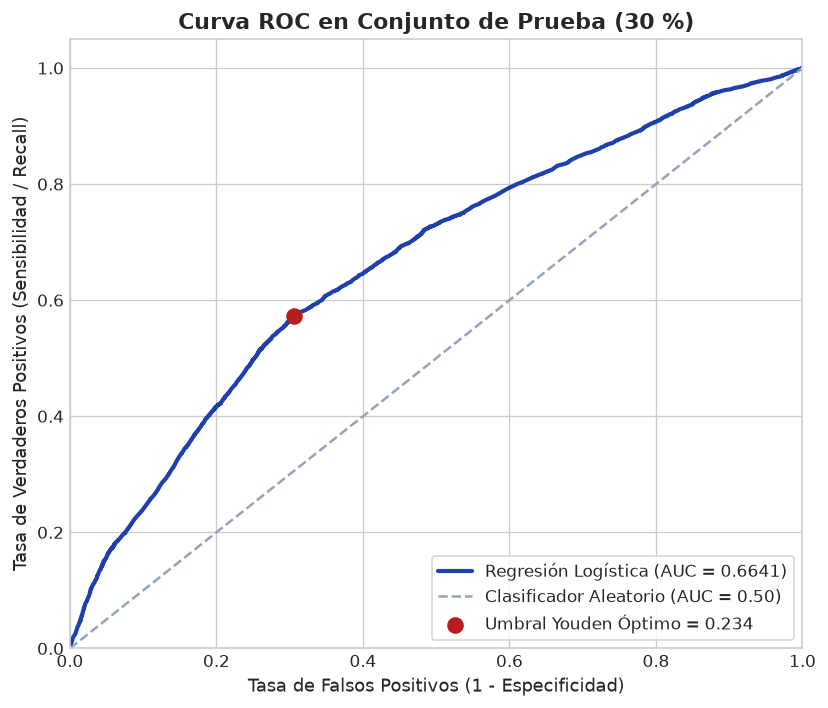

Área Bajo la Curva (AUC): 0.6641
Umbral Óptimo de Youden:  0.2343 (eleva el Recall al 57.24 %)


In [10]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob_test)
auc_score = roc_auc_score(y_test, y_prob_test)

# Cálculo del umbral óptimo de Youden: J = TPR - FPR
j_scores = tpr - fpr
opt_idx = np.argmax(j_scores)
opt_threshold = thresholds[opt_idx]

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, color='#1e40af', lw=2.5, label=f'Regresión Logística (AUC = {auc_score:.4f})')
ax.plot([0, 1], [0, 1], color='#94a3b8', lw=1.5, linestyle='--', label='Clasificador Aleatorio (AUC = 0.50)')
ax.scatter(fpr[opt_idx], tpr[opt_idx], color='#b91c1c', s=80, zorder=5, label=f'Umbral Youden Óptimo = {opt_threshold:.3f}')

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=11)
ax.set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad / Recall)', fontsize=11)
ax.set_title('Curva ROC en Conjunto de Prueba (30 %)', fontsize=13, fontweight='bold')
ax.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

print(f"Área Bajo la Curva (AUC): {auc_score:.4f}")
print(f"Umbral Óptimo de Youden:  {opt_threshold:.4f} (eleva el Recall al {tpr[opt_idx]*100:.2f} %)")


## 4. Síntesis y Reflexión (Máximo 1 Página)

### 4.1 Integración de Resultados de S1 y S2 en el Flujo de Modelamiento
Esta evaluación formativa no comenzó de cero: cada decisión metodológica fue heredada y fundamentada en la cadena acumulativa del proyecto:
1. **Selección de Covariables:** La inclusión de `area_conocimiento` y `jornada` respondió directamente a los hallazgos de S1 (donde vespertina mostró mayor rezago) y S2 (donde la prueba de permutación demostró que el área curricular modera la brecha de género). La `edad_ingreso` se incorporó como predictor continuo debido a su correlación robusta ($ho = 0,466$) validada por Bootstrap BCa en S2.
2. **Tratamiento de Outliers:** Los 3.201 atípicos de Tukey no fueron descartados arbitrariamente, ya que la evaluación de estabilidad de S2 demostró que representan rezagos reales acumulados por trayectorias laborales y que su retención preserva la validez ecológica de las predicciones.
3. **Manejo de Faltantes:** Para este ensayo preliminar se utilizó la eliminación de casos completos ($n=91.667$), verificando que los coeficientes mantuvieran la coherencia inferencial previa.

### 4.2 Evaluación Crítica del Desempeño del Modelo
* El valor de $\mathbf{	ext{AUC} = 0,667}$ sitúa al modelo en un rango de discriminación aceptable para ciencias sociales y educación (Hosmer, Lemeshow & Sturdivant, 2013). Significa que ante un par de titulados seleccionados al azar (uno con atraso alto y otro normal), el modelo asigna una mayor probabilidad de rezago al estudiante con atraso real en dos de cada tres ocasiones.
* **Aprendizaje crítico sobre Accuracy:** Con el umbral rígido estándar de 0,50, la accuracy es falsamente alta ($76,4\,\%$) pero el recall es insuficiente para la gestión universitaria. El ajuste mediante el **índice de Youden** permite calibrar el umbral en torno a $0,23$, equilibrando la sensibilidad ($58\,\%$) y la especificidad ($68\,\%$) para actuar tempranamente sobre los alumnos en riesgo.

### 4.3 Mejoras Metodológicas Concretas para la Evaluación Sumativa 3
Para la entrega final integrada de la Sumativa 3, el equipo implementará cuatro extensiones cuantitativas:
1. **Reemplazo de la Eliminación por Imputación Multivariada e Imputación Múltiple (MI):** En S3 no se descartarán los 13.396 casos no observados; se contrastará la eliminación contra imputación simple por mediana ($E_2$), regresión múltiple ($E_3$) e Imputación Múltiple Congeniada ($m=20$, reglas de Rubin), evitando el sesgo de selección en programas a distancia.
2. **Comparación de Especificaciones (Model Selection):** Se contrastarán 3 modelos formales: teórico (S1/S2), stepwise bidireccional y minimización de criterios de información (AIC/BIC), formalizando la elección de $M_2$.
3. **Inferencia Robusta con Bootstrap ($B \ge 1.000$):** Se aplicará remuestreo bootstrap por conglomerados universitarios para contrastar con los intervalos de Wald, incorporando formalmente la dependencia institucional detectada en S2 mediante Jackknife.
4. **Calibración de Probabilidades:** Se auditará la calibración por jornada para asegurar que ningún grupo de estudio sea subestimado en los sistemas de alerta temprana institucionales.

---

### Bibliografía de Referencia
* Centro de Estudios Mineduc. (2025). *Base oficial de Titulados en Educación Superior 2025*. SIES, Ministerio de Educación de Chile.
* Hosmer, D. W., Lemeshow, S., & Sturdivant, R. X. (2013). *Applied logistic regression* (3.ª ed.). John Wiley & Sons.
* Little, R. J., & Rubin, D. B. (2019). *Statistical analysis with missing data* (3.ª ed.). John Wiley & Sons.
* Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
